# Generalized additive models: other examples

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pygam import PoissonGAM, LinearGAM
from pygam import s, te

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
pi_color    = '#cfe8f3'

## Chicago: air pollution and death rate

Daily data of Chicago, from 1987 to 2000.

| Variable | Description |
|---|---|
| `death` | number of deaths (the response) |
| `time` | time in days |
| `tmpd` | temperature in Fahrenheit |
| `pm10median` | median of the particles of 2.5 to 10 micrometers, per cubic meter (centered) |
| `o3median` | ozone in parts per billion (centered) |

In [3]:
chicago = pd.read_csv('chicago.csv', index_col=0)
chicago = chicago[['time', 'tmpd', 'pm10median', 'o3median', 'death']].dropna()
chicago.describe().round(2)

,time,tmpd,pm10median,o3median,death
count,4863.00,4863.00,4863.00,4863.00,4863.00
mean,75.61,50.16,-0.15,-2.15,115.34
std,1456.96,19.45,19.26,10.14,15.30
min,-2556.50,-16.00,-37.38,-24.78,69.00
25%,-1156.00,35.00,-13.11,-10.18,105.00
50%,106.50,50.50,-3.54,-3.31,114.00
75%,1330.00,67.00,8.30,4.46,124.00
max,2556.50,92.00,320.72,43.69,411.00


In [4]:
# X = [time, tmpd, pm10median, o3median]
X = chicago[['time', 'tmpd', 'pm10median', 'o3median']].to_numpy()
y = chicago['death'].to_numpy()

The number of deaths is a count, so we use a Poisson GAM: a spline for the time (with many basis functions, to follow the seasons), a spline for the particles, and a tensor product for the ozone and the temperature, which allows an interaction between them.

In [5]:
gam = PoissonGAM(s(0, n_splines=200) + te(3, 1) + s(2)).fit(X, y)

In [6]:
# The summary warns that its p-values are known to be too small, we silence that warning
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    gam.summary()

PoissonGAM                                                                                                
=============================================== ==========================================================
Distribution:                       PoissonDist Effective DoF:                                    249.5193
Link Function:                          LogLink Log Likelihood:                                -18742.3323
Number of Samples:                         4863 AIC:                                            37983.7032
                                                AICc:                                           38011.0308
                                                UBRE:                                               3.2727
                                                Scale:                                                 1.0
                                                Pseudo R-Squared:                                   0.4149
Feature Function                  Lam

### Effect of the time

The link is the logarithm, so the exponential of each term multiplies the expected number of deaths.

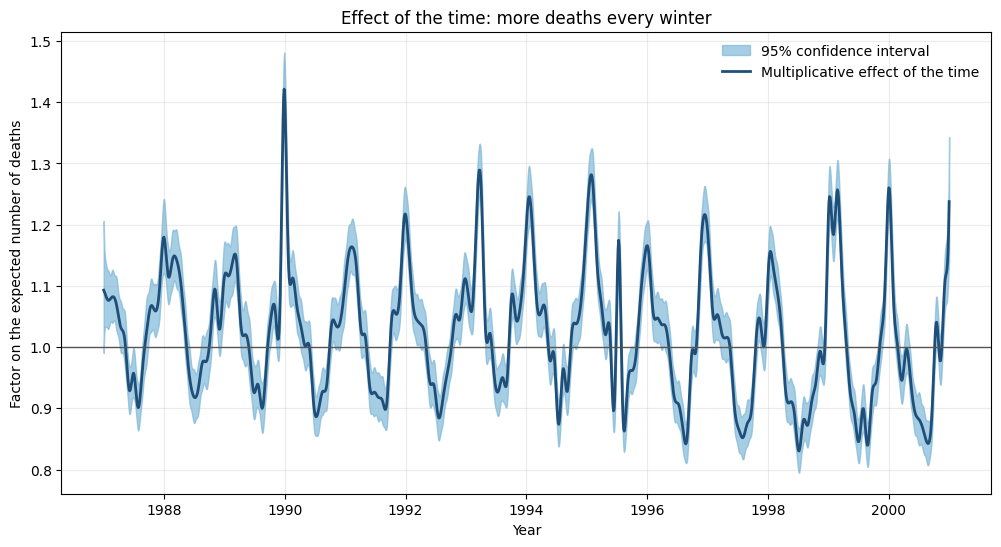

In [7]:
XX = gam.generate_X_grid(term=0, n=1500)
pdep, confi = gam.partial_dependence(term=0, X=XX, width=.95)
years = 1994 + XX[:, 0]/365.25   # time = 0 is the middle of the period

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(years, np.exp(confi[:, 0]), np.exp(confi[:, 1]), color=ci_color, alpha=0.7, label='95% confidence interval')
ax.plot(years, np.exp(pdep), color=line_color, lw=2, label='Multiplicative effect of the time')
ax.axhline(1, color='#555555', lw=1)
ax.set_xlabel('Year')
ax.set_ylabel('Factor on the expected number of deaths')
ax.set_title('Effect of the time: more deaths every winter')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

### Effect of the ozone and the temperature

Text(0.5, 1.0, 'Joint effect of the ozone and the temperature (dots: observed days)')

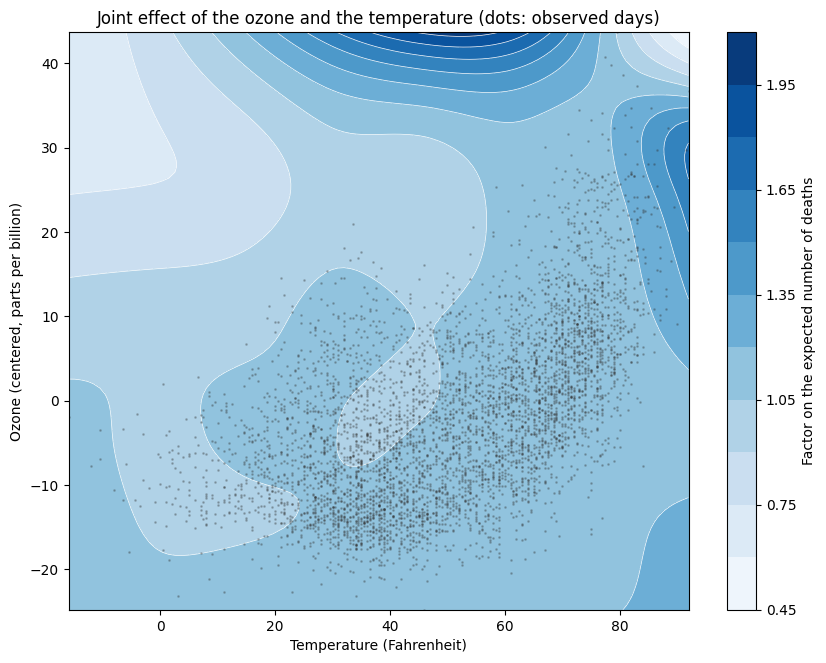

In [8]:
XX = gam.generate_X_grid(term=1, meshgrid=True)
Z = gam.partial_dependence(term=1, X=XX, meshgrid=True)

fig, ax = plt.subplots(figsize=(10, 7.5))
cf = ax.contourf(XX[1], XX[0], np.exp(Z), levels=14, cmap='Blues')
ax.contour(XX[1], XX[0], np.exp(Z), levels=14, colors='white', linewidths=0.5)
ax.plot(X[:, 1], X[:, 3], '.', color='#333333', markersize=2, alpha=0.25)
fig.colorbar(cf, ax=ax, label='Factor on the expected number of deaths')
ax.set_xlabel('Temperature (Fahrenheit)')
ax.set_ylabel('Ozone (centered, parts per billion)')
ax.set_title('Joint effect of the ozone and the temperature (dots: observed days)')

The surface is only reliable where there are data: the corners without observed days are extrapolations.

The same surface in three dimensions

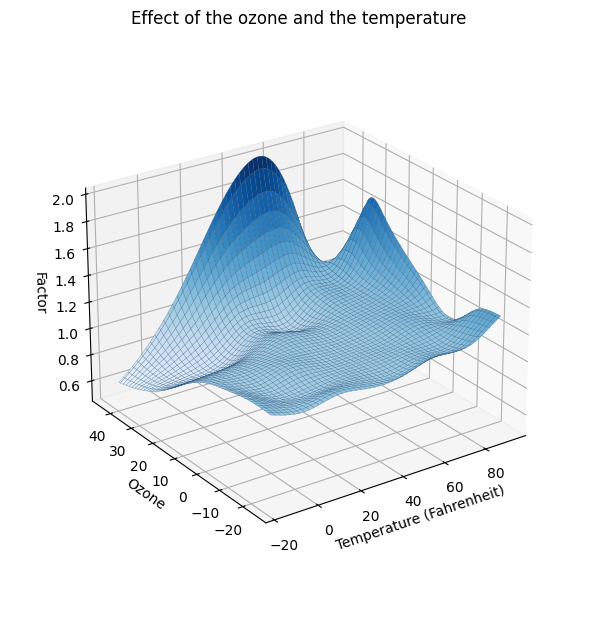

In [9]:
fig = plt.figure(figsize=(10, 7.5))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(XX[1], XX[0], np.exp(Z), cmap='Blues', edgecolor='#1f4e79', linewidth=0.15)
ax.view_init(elev=25, azim=-125)
ax.set_xlabel('Temperature (Fahrenheit)')
ax.set_ylabel('Ozone')
ax.set_zlabel('Factor')
ax.set_box_aspect(None, zoom=0.85)
ax.set_title('Effect of the ozone and the temperature');

### Effect of the particles

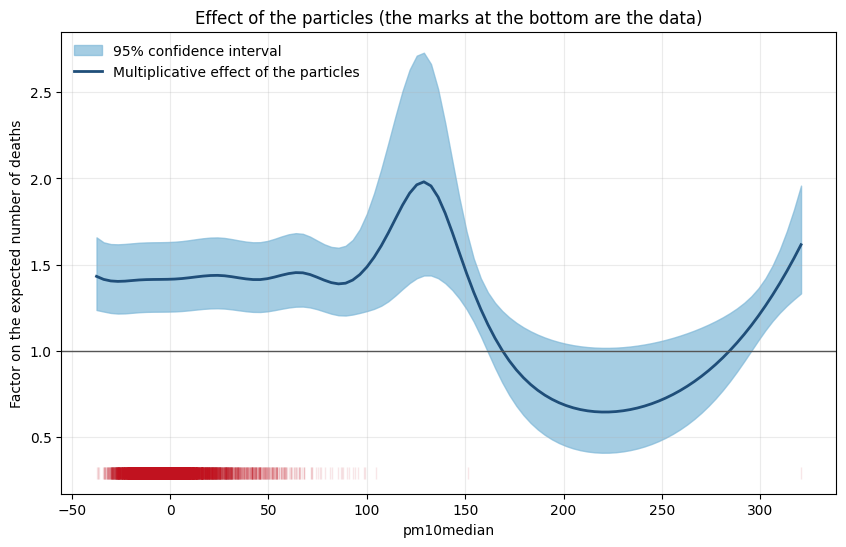

In [10]:
XX = gam.generate_X_grid(term=2)
pdep, confi = gam.partial_dependence(term=2, X=XX, width=.95)

fig, ax = plt.subplots(figsize=(10, 6))
ax.fill_between(XX[:, 2], np.exp(confi[:, 0]), np.exp(confi[:, 1]), color=ci_color, alpha=0.7, label='95% confidence interval')
ax.plot(XX[:, 2], np.exp(pdep), color=line_color, lw=2, label='Multiplicative effect of the particles')
ax.plot(X[:, 2], np.full(len(X), ax.get_ylim()[0]), '|', color=point_color, markersize=8, alpha=0.1)
ax.axhline(1, color='#555555', lw=1)
ax.set_xlabel('pm10median')
ax.set_ylabel('Factor on the expected number of deaths')
ax.set_title('Effect of the particles (the marks at the bottom are the data)')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

### Prediction

The prediction is the exponential of the intercept plus the contributions of the three terms.

In [11]:
XX = np.array([[0, 0, 0, 0]])
a0 = gam.coef_[-1]
a1 = gam.partial_dependence(term=0, X=XX)
a2 = gam.partial_dependence(term=1, X=XX)
a3 = gam.partial_dependence(term=2, X=XX)

print('By hand:  ', np.exp(a1+a2+a3+a0))
print('predict:  ', gam.predict(XX))

By hand:   [129.54458969]
predict:   [129.54458969]


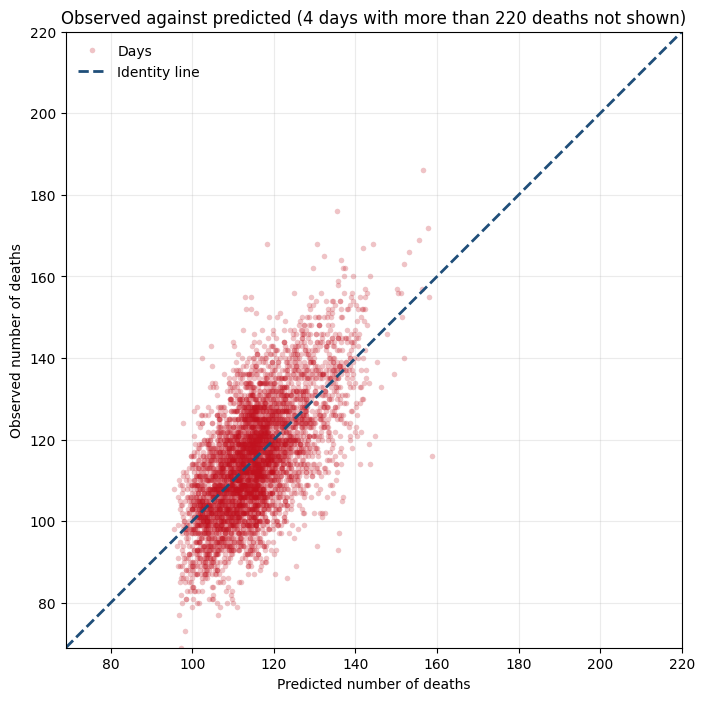

In [12]:
y_hat = gam.predict(X)
limits = [y.min(), 220]

fig, ax = plt.subplots(figsize=(8.5, 8))
ax.plot(y_hat, y, 'o', color=point_color, markersize=4, alpha=0.25, markeredgewidth=0, label='Days')
ax.plot(limits, limits, '--', color=line_color, lw=2, label='Identity line')
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect('equal')
ax.set_xlabel('Predicted number of deaths')
ax.set_ylabel('Observed number of deaths')
ax.set_title(f'Observed against predicted ({(y > 220).sum()} days with more than 220 deaths not shown)')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

## Motorcycle accident: prediction intervals

Acceleration of the head of a dummy during a simulated motorcycle accident, against the time after the impact (data `mcycle`). The variance is clearly not constant, which the intervals of the model do not capture.

In [13]:
mcycle = pd.read_csv('mcycle.csv', index_col=0)
X = mcycle[['times']].to_numpy()
y = mcycle['accel'].to_numpy()

gam = LinearGAM(n_splines=25).gridsearch(X, y, progress=False)
XX = gam.generate_X_grid(term=0, n=500)

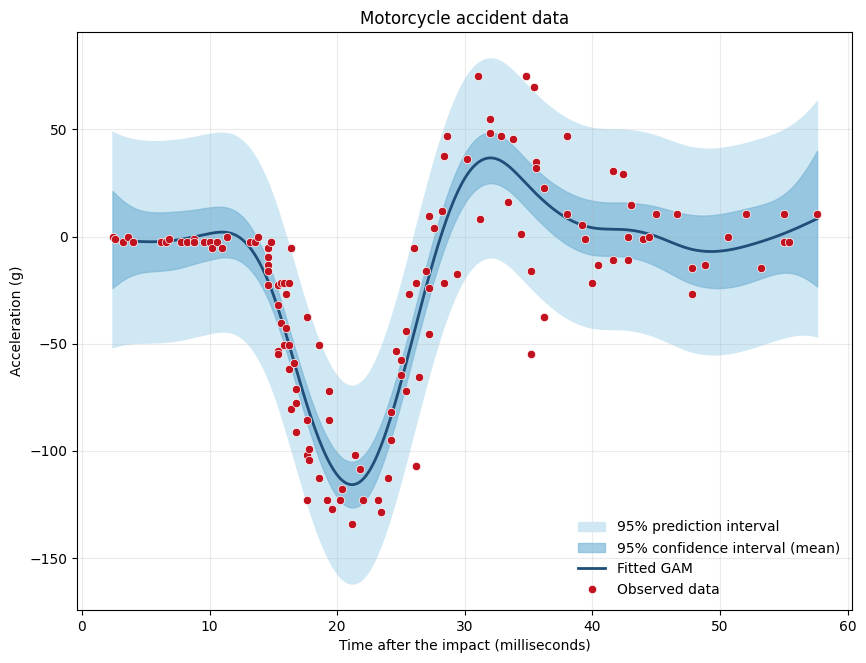

In [14]:
ci = gam.confidence_intervals(XX, width=.95)
pi = gam.prediction_intervals(XX, width=.95)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.fill_between(XX[:, 0], pi[:, 0], pi[:, 1], color=pi_color, label='95% prediction interval')
ax.fill_between(XX[:, 0], ci[:, 0], ci[:, 1], color=ci_color, alpha=0.7, label='95% confidence interval (mean)')
ax.plot(XX[:, 0], gam.predict(XX), color=line_color, lw=2, label='Fitted GAM')
ax.plot(X[:, 0], y, 'o', color=point_color, markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')
ax.set_xlabel('Time after the impact (milliseconds)')
ax.set_ylabel('Acceleration (g)')
ax.set_title('Motorcycle accident data')
ax.legend(loc='lower right', frameon=False)
ax.grid(True, alpha=0.25)

## Old Faithful: a density with a Poisson GAM

Duration of the eruptions of the Old Faithful geyser. We count the eruptions in 200 bins and fit a Poisson GAM to the counts: the fitted curve is a smooth version of the histogram.

In [15]:
faithful = pd.read_csv('faithful.csv', index_col=0)

y, edges = np.histogram(faithful['eruptions'], bins=200)
X = (edges[:-1] + np.diff(edges)/2)[:, None]

gam = PoissonGAM().gridsearch(X, y, progress=False)

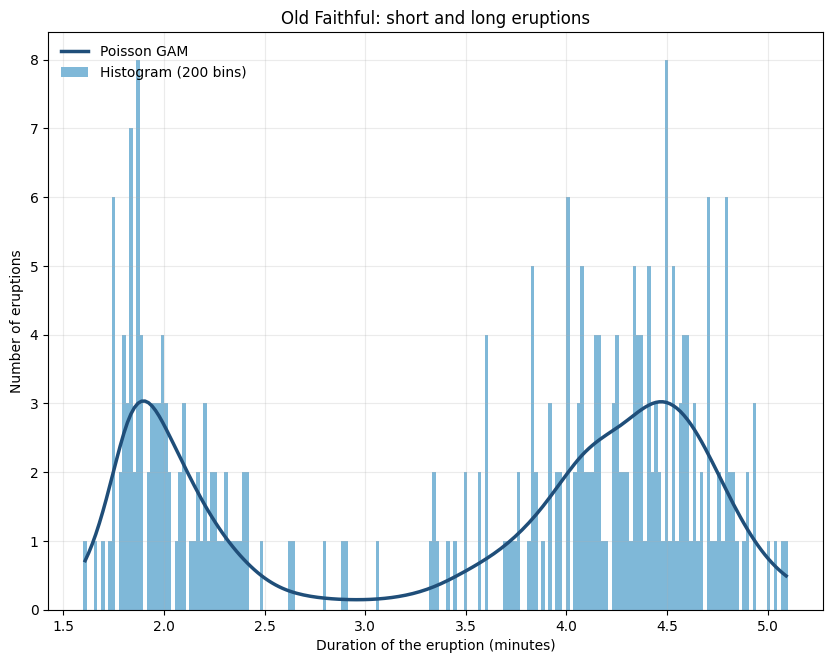

In [16]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.bar(X[:, 0], y, width=np.diff(edges), color=ci_color, label='Histogram (200 bins)')
ax.plot(X[:, 0], gam.predict(X), color=line_color, lw=2.5, label='Poisson GAM')
ax.set_xlabel('Duration of the eruption (minutes)')
ax.set_ylabel('Number of eruptions')
ax.set_title('Old Faithful: short and long eruptions')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)